# Advanced SQL: Window Functions and Interview Classics (DuckDB)

**What you'll learn**

- Window functions at a senior level: `ROW_NUMBER` vs `RANK` vs `DENSE_RANK` on real
  ties, `LAG`/`LEAD`, running totals, moving averages — including the `ROWS` vs
  `RANGE` frame gotcha that silently corrupts both running totals and moving averages.
- The interview classics, solved and *explained*: second-highest value (with the
  ties bug in the naive answer), top-N per group, dedup-to-latest-record, gaps-and-islands
  streaks, month-over-month growth, cumulative distinct users.
- Anti-join and semi-join patterns — and exactly why `NOT IN` returns **zero rows**
  the moment the subquery contains a single `NULL`.
- NULL semantics end-to-end: `COUNT(col)` vs `COUNT(*)`, NULLs in aggregates,
  comparisons, `GROUP BY`, and `IS DISTINCT FROM`.
- Why window functions beat self-joins and correlated subqueries (measured, not
  asserted), and what a decorrelating optimizer like DuckDB's does for you.
- A habit worth copying: every non-trivial SQL result here is **spot-checked against
  pandas** — the same cross-validation you should do when a query feeds a decision.

**Why it matters in interviews**

- SQL screens for senior DS/AS roles lean heavily on windows: "top 3 per group",
  "running total", "users with 3+ consecutive active days" are near-universal.
- Follow-up probes separate levels: *"what happens on ties?"*, *"why did my `NOT IN`
  return nothing?"*, *"`ROWS` or `RANGE` here?"* — this notebook is built around
  those follow-ups.
- Interviewers increasingly ask you to *debug* a broken query (NULL traps,
  left-join-turned-inner) rather than write one from scratch.
- Explaining *why* a window beats a self-join (one sort vs a quadratic join) signals
  you understand execution, not just syntax.

Everything runs live against an in-memory DuckDB. Product-analytics SQL (retention,
funnels, sessionization) is in `02_sql_product_analytics.ipynb`; when data outgrows
one machine, the same ideas move to Spark in `03_pyspark_fundamentals.ipynb`.

In [1]:
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

con = duckdb.connect()  # in-memory database


def q(sql: str) -> pd.DataFrame:
    """Run SQL against the in-memory DuckDB and return a pandas DataFrame."""
    return con.execute(sql).df()

## 1. Build a realistic e-commerce schema

Four core tables, the same shape you would meet at any marketplace or DTC company:

| table | grain | notes |
|---|---|---|
| `users` | one row per registered user | signup date, country, acquisition channel |
| `orders` | one row per order | **guest checkouts have `user_id = NULL`** — this is deliberate and will matter |
| `order_items` | one row per order line | quantity, unit price, line amount |
| `events` | one row per clickstream event | last ~6 months only, like a typical retention window |

Design choices that set up later sections:

- `orders.discount_pct` is NULL for non-discounted orders (NULL-aggregate traps).
- 150 "habitual" buyers are seeded with runs of orders on consecutive days
  (ground truth for the gaps-and-islands section — we *know* at least 150 users
  must show a 3+ day purchase streak).
- `orders.amount` is stored denormalized *and* derivable from `order_items`, so we
  can reconcile the two — exactly the kind of consistency check you should run on a
  real warehouse before trusting a table.

In [2]:
N_USERS, N_PRODUCTS, N_HABITUAL, N_GUEST_ORDERS = 4_000, 60, 150, 400
START = pd.Timestamp("2024-01-01")
END = pd.Timestamp("2025-06-30")
HORIZON_DAYS = (END - START).days  # 546

# --- users ---------------------------------------------------------------
signup_offset = rng.integers(0, 500, N_USERS)
users_df = pd.DataFrame({
    "user_id": np.arange(1, N_USERS + 1),
    "signup_date": START + pd.to_timedelta(signup_offset, unit="D"),
    "country": rng.choice(["US", "DE", "GB", "FR", "NL"], N_USERS,
                          p=[0.38, 0.22, 0.18, 0.12, 0.10]),
    "channel": rng.choice(["paid_search", "organic", "referral", "social"], N_USERS,
                          p=[0.35, 0.35, 0.18, 0.12]),
})

# --- products (skewed popularity -> clear top-N structure) ---------------
categories = rng.choice(["electronics", "home", "fashion", "beauty", "sports", "grocery"],
                        N_PRODUCTS)
products_df = pd.DataFrame({
    "product_id": np.arange(1, N_PRODUCTS + 1),
    "product_name": [f"P{i:03d}" for i in range(1, N_PRODUCTS + 1)],
    "category": categories,
    "base_price": np.round(np.clip(np.exp(rng.normal(3.3, 0.8, N_PRODUCTS)), 4, 800), 2),
})
popularity = rng.dirichlet(np.full(N_PRODUCTS, 0.5))

# --- orders: ~55% of users ever buy; inter-purchase gaps ~ Exponential ---
is_buyer = rng.random(N_USERS) < 0.55
order_user, order_day = [], []
for uid, s_off, buyer in zip(users_df.user_id, signup_offset, is_buyer):
    if not buyer:
        continue
    n_ord = 1 + rng.negative_binomial(2.0, 0.25)
    days = s_off + 3 + np.cumsum(rng.exponential(30, n_ord))
    days = days[days <= HORIZON_DAYS].astype(int)
    order_user.extend([uid] * len(days))
    order_day.extend(days)

# habitual buyers: runs of orders on consecutive days (ground truth for streaks)
eligible = users_df.user_id[is_buyer & (signup_offset <= 400)].to_numpy()
habitual_users = rng.choice(eligible, N_HABITUAL, replace=False)
for uid in habitual_users:
    s_off = int(signup_offset[uid - 1])
    run_len = int(rng.integers(3, 10))
    day0 = min(s_off + 3 + int(rng.integers(0, 380)), HORIZON_DAYS - run_len)
    for d in range(day0, day0 + run_len):
        order_user.append(uid)
        order_day.append(d)

# guest checkouts: user_id is NULL (this powers the NOT IN trap later)
order_user.extend([pd.NA] * N_GUEST_ORDERS)
order_day.extend(rng.integers(0, HORIZON_DAYS + 1, N_GUEST_ORDERS).tolist())

n_orders = len(order_day)
order_ts = (START + pd.to_timedelta(order_day, unit="D")
            + pd.to_timedelta(rng.integers(8 * 3600, 23 * 3600, n_orders), unit="s"))
orders_df = pd.DataFrame({
    "user_id": pd.array(order_user, dtype="Int64"),
    "order_ts": order_ts,
    "status": rng.choice(["completed", "returned", "cancelled"], n_orders,
                         p=[0.88, 0.07, 0.05]),
    "discount_pct": pd.array(np.where(rng.random(n_orders) < 0.25,
                                      rng.choice([5, 10, 15, 20], n_orders), None),
                             dtype="Int64"),
}).sort_values("order_ts", ignore_index=True)
orders_df.insert(0, "order_id", np.arange(1, n_orders + 1))

# --- order_items ---------------------------------------------------------
n_items = rng.integers(1, 5, n_orders)
tot = int(n_items.sum())
prod_idx = rng.choice(N_PRODUCTS, tot, p=popularity)
qty = rng.integers(1, 4, tot)
unit_price = np.round(products_df.base_price.to_numpy()[prod_idx]
                      * rng.uniform(0.85, 1.0, tot), 2)
items_df = pd.DataFrame({
    "item_id": np.arange(1, tot + 1),
    "order_id": np.repeat(orders_df.order_id.to_numpy(), n_items),
    "product_id": prod_idx + 1,
    "quantity": qty,
    "unit_price": unit_price,
    "line_amount": np.round(qty * unit_price, 2),
})
orders_df["amount"] = np.round(
    items_df.groupby("order_id").line_amount.sum().reindex(orders_df.order_id).to_numpy(), 2)

# --- events: daily activity grid for Jan-Jun 2025 ------------------------
EV_START, EV_DAYS = pd.Timestamp("2025-01-01"), 181
act_rate = rng.beta(1.3, 6.5, N_USERS)
active = rng.random((N_USERS, EV_DAYS)) < act_rate[:, None]
signup_rel = ((users_df.signup_date - EV_START).dt.days).to_numpy()
active &= np.arange(EV_DAYS)[None, :] >= signup_rel[:, None]  # no activity pre-signup
u_idx, d_idx = np.nonzero(active)
ev_per_day = 1 + rng.poisson(0.8, len(u_idx))
n_ev = int(ev_per_day.sum())
events_df = pd.DataFrame({
    "event_id": np.arange(1, n_ev + 1),
    "user_id": np.repeat(u_idx + 1, ev_per_day),
    "event_ts": (EV_START + pd.to_timedelta(np.repeat(d_idx, ev_per_day), unit="D")
                 + pd.to_timedelta(rng.integers(6 * 3600, 86_399, n_ev), unit="s")),
    "event_type": rng.choice(["page_view", "search", "add_to_cart", "checkout"],
                             n_ev, p=[0.55, 0.20, 0.15, 0.10]),
})

# --- load into DuckDB ----------------------------------------------------
con.execute("CREATE TABLE users AS SELECT user_id, signup_date::DATE AS signup_date, "
            "country, channel FROM users_df")
con.execute("CREATE TABLE products AS SELECT * FROM products_df")
con.execute("CREATE TABLE orders AS SELECT * FROM orders_df")
con.execute("CREATE TABLE order_items AS SELECT * FROM items_df")
con.execute("CREATE TABLE events AS SELECT * FROM events_df")

print(q("""
SELECT (SELECT count(*) FROM users)       AS users,
       (SELECT count(*) FROM products)    AS products,
       (SELECT count(*) FROM orders)      AS orders,
       (SELECT count(*) FROM order_items) AS order_items,
       (SELECT count(*) FROM events)      AS events
""").to_string(index=False))
q("DESCRIBE orders")

 users  products  orders  order_items  events
  4000        60   12929        32359  192988


,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,user_id,BIGINT,YES,None,None,None
2,order_ts,TIMESTAMP_NS,YES,None,None,None
3,status,VARCHAR,YES,None,None,None
4,discount_pct,BIGINT,YES,None,None,None
5,amount,DOUBLE,YES,None,None,None


### Trust, but verify: reconcile SQL against pandas

Before analyzing anything, cross-check the warehouse against an independent
computation. Here that means: SQL aggregates must match pandas aggregates on the
source frames, and the denormalized `orders.amount` must equal the sum of its order
lines. On the job the analogue is reconciling a new mart against the raw event log —
do it *once per table*, then you can trust the fast path.

In [3]:
sql_stats = q("""
SELECT round(sum(amount), 2)  AS total_revenue,
       count(*)               AS n_orders,
       count(user_id)         AS n_orders_with_user
FROM orders
""")
pdf_total = round(orders_df.amount.sum(), 2)
assert abs(sql_stats.total_revenue[0] - pdf_total) < 0.01
assert sql_stats.n_orders[0] == len(orders_df)
assert sql_stats.n_orders_with_user[0] == orders_df.user_id.notna().sum()

recon = q("""
SELECT max(abs(o.amount - i.item_total)) AS max_abs_gap
FROM orders o
JOIN (SELECT order_id, sum(line_amount) AS item_total
      FROM order_items GROUP BY order_id) i USING (order_id)
""")
assert recon.max_abs_gap[0] < 0.01

print(f"SQL total revenue      : {sql_stats.total_revenue[0]:,.2f}")
print(f"pandas total revenue   : {pdf_total:,.2f}")
print(f"orders.amount vs items : max abs gap = {recon.max_abs_gap[0]:.4f}")
print(f"guest orders (NULL uid): {sql_stats.n_orders[0] - sql_stats.n_orders_with_user[0]}")
print("All reconciliation checks passed.")

SQL total revenue      : 1,202,819.15
pandas total revenue   : 1,202,819.15
orders.amount vs items : max abs gap = 0.0000
guest orders (NULL uid): 400
All reconciliation checks passed.


## 2. Window functions mastery

A window function computes a value **per row** over a set of related rows, without
collapsing them the way `GROUP BY` does. The full anatomy:

```sql
fn(...) OVER (PARTITION BY ...   -- restart per group
              ORDER BY ...       -- ordering within the partition
              ROWS|RANGE BETWEEN ... AND ...)  -- the frame (which rows fn sees)
```

Senior candidates get probed on the three parts most people never think about:
what happens on **ties**, what the **default frame** is, and when `ROWS` and
`RANGE` disagree.

### 2.1 ROW_NUMBER vs RANK vs DENSE_RANK — behavior on ties

"Top customers in the Netherlands by number of completed orders" — a count metric,
so ties are guaranteed, and the three ranking functions immediately diverge:

- `ROW_NUMBER` — 1, 2, 3, ... always unique; **ties broken arbitrarily** unless you
  add a deterministic tiebreaker to `ORDER BY`.
- `RANK` — ties share a rank, then the rank **skips** (1, 2, 2, 4): Olympic medals.
- `DENSE_RANK` — ties share a rank, **no gaps** (1, 2, 2, 3): "how many distinct
  levels above me".

In [4]:
nl_leaderboard = q("""
WITH nl_counts AS (
    SELECT u.user_id, count(*) AS n_completed
    FROM users u
    JOIN orders o USING (user_id)
    WHERE u.country = 'NL' AND o.status = 'completed'
    GROUP BY u.user_id
)
SELECT user_id, n_completed,
       row_number() OVER (ORDER BY n_completed DESC, user_id) AS row_num,
       rank()       OVER (ORDER BY n_completed DESC)          AS rnk,
       dense_rank() OVER (ORDER BY n_completed DESC)          AS dense_rnk
FROM nl_counts
ORDER BY n_completed DESC, user_id
""")
assert (nl_leaderboard.rnk != nl_leaderboard.dense_rnk).any(), "expected ties"
print(nl_leaderboard.head(12).to_string(index=False))
first_gap = nl_leaderboard.loc[nl_leaderboard.rnk != nl_leaderboard.dense_rnk].iloc[0]
print(f"\nFirst divergence: n_completed={first_gap.n_completed} has "
      f"rank={first_gap.rnk} but dense_rank={first_gap.dense_rnk} -- "
      f"rank runs {first_gap.rnk - first_gap.dense_rnk} ahead because of earlier ties.")

 user_id  n_completed  row_num  rnk  dense_rnk
    1035           20        1    1          1
     218           16        2    2          2
    3782           16        3    2          2
    2794           15        4    4          3
     104           14        5    5          4
    1563           14        6    5          4
    3356           14        7    5          4
     620           13        8    8          5
     902           12        9    9          6
    1511           12       10    9          6
    3232           12       11    9          6
    3729           12       12    9          6

First divergence: n_completed=15 has rank=4 but dense_rank=3 -- rank runs 1 ahead because of earlier ties.


Rules of thumb worth saying out loud in an interview:

- **"Exactly N rows per group"** (dedup, top-N with a hard cap) → `ROW_NUMBER`,
  *always* with a unique tiebreaker in the `ORDER BY` — otherwise the result is
  non-deterministic across runs and engines.
- **"Everyone tied for the podium"** → `RANK` (`<= 3` may return more than 3 rows).
- **"Nth highest distinct value"** → `DENSE_RANK` (ties collapse to one level).

Note the `row_number() OVER (ORDER BY n_completed DESC, user_id)` above: the
`user_id` tiebreaker is what makes this notebook reproducible.

### 2.2 LAG and LEAD: inter-purchase gaps

`LAG`/`LEAD` pull values from neighboring rows in the partition order — the SQL
equivalent of `groupby().shift()`. The canonical use: time between consecutive
orders per user, which feeds churn definitions and reactivation flags
(see `../08_product_analytics/02_churn_survival.ipynb` for what to do with them).

In [5]:
gaps = q("""
SELECT user_id, order_id, order_ts,
       lag(order_ts)  OVER w AS prev_ts,
       date_diff('day', lag(order_ts) OVER w, order_ts) AS days_since_prev,
       lead(order_ts) OVER w AS next_ts
FROM orders
WHERE user_id IS NOT NULL
WINDOW w AS (PARTITION BY user_id ORDER BY order_ts, order_id)
ORDER BY user_id, order_ts
""")
print(gaps.head(8).to_string(index=False))

gap_summary = q("""
WITH g AS (
    SELECT date_diff('day', lag(order_ts) OVER (PARTITION BY user_id ORDER BY order_ts, order_id),
                     order_ts) AS days_since_prev
    FROM orders WHERE user_id IS NOT NULL
)
SELECT count(*) FILTER (WHERE days_since_prev IS NOT NULL)  AS n_gaps,
       round(median(days_since_prev), 1)                    AS median_gap_days,
       round(avg((days_since_prev > 60)::INT), 3)           AS share_gaps_over_60d
FROM g
""")
print("\n" + gap_summary.to_string(index=False))

# spot-check LAG against pandas groupby().shift()
# note: date_diff('day', t1, t2) counts calendar-day boundaries crossed, so the
# pandas equivalent works on normalized dates, not raw timestamp deltas
reg = (orders_df[orders_df.user_id.notna()]
       .sort_values(["user_id", "order_ts", "order_id"])
       .assign(d=lambda f: f.order_ts.dt.normalize()))
pd_gap = (reg.d - reg.groupby("user_id").d.shift()).dt.days
assert np.array_equal(
    gaps.sort_values(["user_id", "order_ts"]).days_since_prev.to_numpy(dtype=float),
    pd_gap.to_numpy(dtype=float), equal_nan=True)
print("\nLAG matches pandas groupby().shift() on every row.")

 user_id  order_id            order_ts             prev_ts  days_since_prev             next_ts
       2      9015 2025-02-26 20:56:34                 NaT             <NA> 2025-04-16 11:44:34
       2     10491 2025-04-16 11:44:34 2025-02-26 20:56:34               49 2025-05-15 18:25:39
       2     11444 2025-05-15 18:25:39 2025-04-16 11:44:34               29                 NaT
       3      7032 2024-12-27 08:47:20                 NaT             <NA>                 NaT
      12     11071 2025-05-05 10:09:37                 NaT             <NA> 2025-05-14 15:57:41
      12     11404 2025-05-14 15:57:41 2025-05-05 10:09:37                9 2025-05-17 09:47:19
      12     11485 2025-05-17 09:47:19 2025-05-14 15:57:41                3 2025-05-30 14:42:00
      12     11921 2025-05-30 14:42:00 2025-05-17 09:47:19               13 2025-06-02 14:30:48

 n_gaps  median_gap_days  share_gaps_over_60d
  10379             17.0                0.111

LAG matches pandas groupby().shift() on ev

Two things interviewers listen for: the first order per user has `LAG = NULL`
(handle it explicitly — here `FILTER`/`count` just drop it), and the `WINDOW w AS`
clause, which names one window spec instead of repeating it — small, but it reads
as fluency.

### 2.3 Running totals — and the default-frame trap

The classic phrasing: *"write a running total of revenue by date."* The naive
answer `SUM(amount) OVER (ORDER BY order_date)` is subtly wrong. With an
`ORDER BY` and no explicit frame, the SQL standard default is

`RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`

and `RANGE` includes **all peers of the current row** — every row that ties on the
`ORDER BY` key. Order on a *date* (many orders per day) and every order that day
shows the same "running" total: the day's *closing* balance, not a row-level
running sum.

In [6]:
one_day_demo = q("""
SELECT order_id, order_ts::DATE AS order_date, amount,
       sum(amount) OVER (ORDER BY order_ts::DATE)  AS rt_default_range,   -- peers jump together
       sum(amount) OVER (ORDER BY order_ts::DATE
                         ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS rt_rows_untied,
       sum(amount) OVER (ORDER BY order_ts::DATE, order_id
                         ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS rt_deterministic
FROM orders
WHERE order_ts::DATE BETWEEN DATE '2024-03-04' AND DATE '2024-03-05'
ORDER BY order_date, order_id
""")
print(one_day_demo.head(12).round(2).to_string(index=False))

per_day = one_day_demo.groupby("order_date").rt_default_range.nunique()
assert (per_day == 1).all()  # default frame: one value per day, repeated on every row
print("\nDefault RANGE frame: every order on a given date shows the same 'running' total")
print("(all peers included). ROWS gives row-level accumulation; adding order_id to the")
print("ORDER BY makes the accumulation order deterministic as well.")

 order_id order_date  amount  rt_default_range  rt_rows_untied  rt_deterministic
      293 2024-03-04  227.81           1540.64          227.81            227.81
      294 2024-03-04  234.45           1540.64          462.26            462.26
      295 2024-03-04  200.33           1540.64          662.59            662.59
      296 2024-03-04  119.38           1540.64          781.97            781.97
      297 2024-03-04  110.65           1540.64          892.62            892.62
      298 2024-03-04  168.50           1540.64         1061.12           1061.12
      299 2024-03-04   39.92           1540.64         1101.04           1101.04
      300 2024-03-04  137.11           1540.64         1238.15           1238.15
      301 2024-03-04  133.99           1540.64         1372.14           1372.14
      302 2024-03-04  168.50           1540.64         1540.64           1540.64
      303 2024-03-05  222.21           3268.89         1762.85           1762.85
      304 2024-03-05  122.38

Three correct variants, depending on what was actually asked:

1. **Row-level running total** → `ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`
   *plus a unique tiebreaker* in `ORDER BY` (otherwise the order within a day, and
   hence every intermediate value, is arbitrary).
2. **Daily cumulative revenue** → aggregate to one row per day first, then window
   (below). This is usually what the business question means.
3. **"Balance as of each date, shown on every order"** → the default `RANGE` frame
   is *exactly right*. Knowing when the "trap" is the requirement is the senior move.

In [7]:
con.execute("""
CREATE TABLE daily_revenue AS
SELECT order_ts::DATE AS d, sum(amount) AS revenue, count(*) AS n_orders
FROM orders
WHERE status = 'completed'
GROUP BY 1 ORDER BY 1
""")
cum = q("""
SELECT d, revenue,
       sum(revenue) OVER (ORDER BY d) AS cumulative_revenue  -- one row per day: ties impossible
FROM daily_revenue ORDER BY d
""")
# spot-check vs pandas cumsum
pd_cum = (orders_df[orders_df.status == "completed"]
          .assign(d=orders_df.order_ts.dt.normalize())
          .groupby("d").amount.sum().sort_index().cumsum())
assert np.allclose(cum.cumulative_revenue.to_numpy(), pd_cum.to_numpy())
print(cum.tail(3).round(2).to_string(index=False))
print("\nCumulative daily revenue matches pandas .cumsum() exactly "
      f"({len(cum)} days). At one row per day, the default frame is safe.")

         d  revenue  cumulative_revenue
2025-06-27  4274.15          1047633.61
2025-06-28  3747.36          1051380.97
2025-06-29  5148.83          1056529.80

Cumulative daily revenue matches pandas .cumsum() exactly (543 days). At one row per day, the default frame is safe.


### 2.4 Moving averages: ROWS vs RANGE is a *correctness* choice

The follow-up trap: *"now give me the trailing 7-day average."* On a daily table
`ROWS BETWEEN 6 PRECEDING AND CURRENT ROW` means "last 7 **rows**". That equals
"last 7 **days**" only if every day has a row. Product-level or segment-level
series have gaps (days with zero sales are simply absent), and then the `ROWS`
frame silently stretches over more calendar time — averaging, say, 7 rows spread
across 3 weeks.

`RANGE BETWEEN INTERVAL 6 DAYS PRECEDING AND CURRENT ROW` frames by *value*
(calendar distance), which is what "7-day average" means. We pick a mid-tail
product whose daily series genuinely has gaps and compute both.

In [8]:
pid = int(q("""
SELECT oi.product_id,
       count(DISTINCT o.order_ts::DATE) / 547.0 AS day_coverage
FROM order_items oi JOIN orders o USING (order_id)
WHERE o.status = 'completed'
GROUP BY 1
ORDER BY abs(day_coverage - 0.60), oi.product_id
LIMIT 1
""").product_id[0])

con.execute(f"""
CREATE TABLE product_daily AS
SELECT o.order_ts::DATE AS d, sum(oi.line_amount) AS revenue
FROM order_items oi JOIN orders o USING (order_id)
WHERE oi.product_id = {pid} AND o.status = 'completed'
GROUP BY 1 ORDER BY 1
""")
ma = q("""
SELECT d, revenue,
       avg(revenue) OVER (ORDER BY d ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)  AS ma7_rows,
       avg(revenue) OVER (ORDER BY d RANGE BETWEEN INTERVAL 6 DAYS PRECEDING
                                            AND CURRENT ROW)                    AS ma7_range,
       count(*)     OVER (ORDER BY d RANGE BETWEEN INTERVAL 6 DAYS PRECEDING
                                            AND CURRENT ROW)                    AS days_in_range,
       date_diff('day', min(d) OVER (ORDER BY d ROWS BETWEEN 6 PRECEDING AND CURRENT ROW),
                 d) + 1                                                          AS days_spanned_by_rows
FROM product_daily ORDER BY d
""")
n_days, n_cal = len(ma), (ma.d.max() - ma.d.min()).days + 1
print(f"Product P{pid:03d}: {n_days} selling days across {n_cal} calendar days "
      f"({n_days / n_cal:.0%} coverage) -> the ROWS frame must overreach.")
worst = ma.loc[ma.days_spanned_by_rows.idxmax()]
print(f"Worst case: the '7-row' frame ending {worst.d.date()} actually spans "
      f"{int(worst.days_spanned_by_rows)} calendar days.")
assert (ma.days_spanned_by_rows > 7).any(), "expected gaps to stretch the ROWS frame"
print("\nRows where the ROWS frame stretches furthest past 7 calendar days:")
div = ma.nlargest(5, "days_spanned_by_rows").sort_values("d")
print(div[["d", "revenue", "ma7_rows", "ma7_range", "days_in_range",
           "days_spanned_by_rows"]].round(2).to_string(index=False))

Product P055: 325 selling days across 537 calendar days (61% coverage) -> the ROWS frame must overreach.
Worst case: the '7-row' frame ending 2024-02-13 actually spans 35 calendar days.

Rows where the ROWS frame stretches furthest past 7 calendar days:
         d  revenue  ma7_rows  ma7_range  days_in_range  days_spanned_by_rows
2024-02-08    40.82     98.56      80.83              2                    30
2024-02-10   113.10    101.46      91.59              3                    32
2024-02-11    84.48     98.63      89.81              4                    33
2024-02-13    82.00     96.26      80.10              4                    35
2024-02-18    40.30     85.86      61.15              2                    32


RANGE INTERVAL 6 DAYS moving average == pandas .rolling('7D').mean() on all rows.


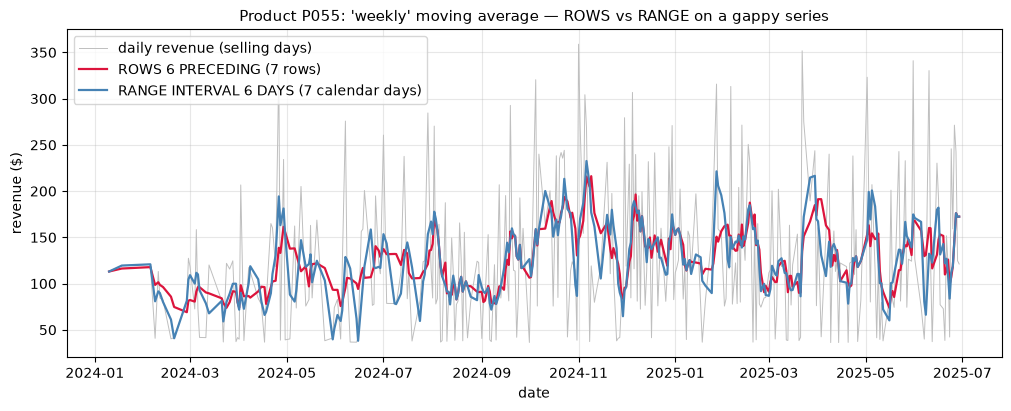

In [9]:
# Spot-check the RANGE version against pandas' time-based rolling window
pd_ma = (ma.set_index(pd.to_datetime(ma.d)).revenue.rolling("7D").mean())
assert np.allclose(ma.ma7_range.to_numpy(), pd_ma.to_numpy())
print("RANGE INTERVAL 6 DAYS moving average == pandas .rolling('7D').mean() on all rows.")

fig, ax = plt.subplots(figsize=(10, 4))
dts = pd.to_datetime(ma.d)
ax.plot(dts, ma.revenue, lw=0.7, color="0.75", label="daily revenue (selling days)")
ax.plot(dts, ma.ma7_rows, color="crimson", lw=1.6, label="ROWS 6 PRECEDING (7 rows)")
ax.plot(dts, ma.ma7_range, color="steelblue", lw=1.6, label="RANGE INTERVAL 6 DAYS (7 calendar days)")
ax.set(title=f"Product P{pid:03d}: 'weekly' moving average — ROWS vs RANGE on a gappy series",
       xlabel="date", ylabel="revenue ($)")
ax.legend()
plt.show()

The red (`ROWS`) line is systematically smoother and *laggier*: after every gap it
is still averaging stale weeks. Neither line is "the" 7-day average of *total*
demand, though — days with zero sales are missing entirely, so the calendar-true
average over all days requires joining to a date spine
(`generate_series(DATE '...', DATE '...', INTERVAL 1 DAY)`) first and treating
missing days as 0. That spine pattern is developed properly in
`02_sql_product_analytics.ipynb`.

Frame cheat sheet: **`ROWS` counts rows; `RANGE` measures distance in the `ORDER BY`
value; the default with `ORDER BY` is `RANGE ... CURRENT ROW`, which includes peers.**

### 2.5 NTILE: equal-count buckets

`NTILE(n)` deals rows into n buckets of (near-)equal **count** — not equal width,
and it will happily split rows that tie on the `ORDER BY` value across buckets.
Typical use: spend quartiles for a quick whale analysis (for principled
segmentation see `../08_product_analytics/04_segmentation_clustering.ipynb`).

In [10]:
quartiles = q("""
WITH user_spend AS (
    SELECT u.user_id,
           coalesce(sum(o.amount) FILTER (WHERE o.status = 'completed'), 0) AS spend
    FROM users u
    LEFT JOIN orders o USING (user_id)
    GROUP BY u.user_id
),
tiled AS (
    SELECT user_id, spend,
           ntile(4) OVER (ORDER BY spend, user_id) AS spend_quartile
    FROM user_spend
)
SELECT spend_quartile,
       count(*)              AS n_users,
       round(min(spend), 2)  AS min_spend,
       round(avg(spend), 2)  AS avg_spend,
       round(max(spend), 2)  AS max_spend,
       round(100 * sum(spend) / sum(sum(spend)) OVER (), 1) AS pct_of_revenue
FROM tiled
GROUP BY 1 ORDER BY 1
""")
print(quartiles.to_string(index=False))
top_share = quartiles.pct_of_revenue.iloc[-1]
print(f"\nTop quartile of users carries {top_share:.1f}% of registered-user revenue.")
print("Note the equal bucket sizes (+/-1) and that never-purchasers pack the bottom")
print("buckets: ties on spend=0 are split across quartile boundaries arbitrarily --")
print("the user_id tiebreaker only makes the split reproducible, not meaningful.")

 spend_quartile  n_users  min_spend  avg_spend  max_spend  pct_of_revenue
              1     1000       0.00       0.00       0.00             0.0
              2     1000       0.00       4.82      67.03             0.5
              3     1000      67.20     241.39     430.18            23.5
              4     1000     431.16     779.39    2345.62            76.0

Top quartile of users carries 76.0% of registered-user revenue.
Note the equal bucket sizes (+/-1) and that never-purchasers pack the bottom
buckets: ties on spend=0 are split across quartile boundaries arbitrarily --
the user_id tiebreaker only makes the split reproducible, not meaningful.


Also note `sum(sum(spend)) OVER ()` — a window over an aggregate. Aggregates
evaluate first, then windows see the grouped rows; this is the standard way to get
"share of total" in one pass.

## 3. Interview classics, solved and explained

### 3.1 Second-highest value — and why the naive answer is wrong

The most-asked SQL question in existence, usually on a salary table, so we use one
(with deliberate ties and a NULL — both edge cases interviewers poke at).

In [11]:
con.execute("""
CREATE TABLE employees AS
SELECT * FROM (VALUES
    (1, 'data', 120), (2, 'data', 145), (3, 'data', 145), (4, 'data', 110),
    (5, 'eng', 160),  (6, 'eng', 160),  (7, 'eng', 150),  (8, 'eng', 138),
    (9, 'ops', 95),   (10, 'ops', 95),  (11, 'ops', NULL)
) t(emp_id, dept, salary)
""")

naive = q("SELECT salary FROM employees ORDER BY salary DESC NULLS LAST LIMIT 1 OFFSET 1")
v_max = q("""SELECT max(salary) AS s FROM employees
             WHERE salary < (SELECT max(salary) FROM employees)""")
v_distinct = q("""SELECT DISTINCT salary FROM employees WHERE salary IS NOT NULL
                  ORDER BY salary DESC LIMIT 1 OFFSET 1""")
v_dense = q("""
SELECT DISTINCT salary AS s FROM (
    SELECT salary, dense_rank() OVER (ORDER BY salary DESC NULLS LAST) AS dr
    FROM employees)
WHERE dr = 2
""")
print(f"naive LIMIT/OFFSET      : {naive.salary[0]}   <- WRONG: top salary 160 is tied")
print(f"max below max           : {v_max.s[0]}")
print(f"DISTINCT + OFFSET       : {v_distinct.salary[0]}")
print(f"dense_rank() = 2        : {v_dense.s[0]}")
assert v_max.s[0] == v_distinct.salary[0] == v_dense.s[0] == 150
assert naive.salary[0] == 160  # the classic ties bug

naive LIMIT/OFFSET      : 160   <- WRONG: top salary 160 is tied
max below max           : 150
DISTINCT + OFFSET       : 150
dense_rank() = 2        : 150


Talking points that earn senior credit:

- The naive `ORDER BY salary DESC LIMIT 1 OFFSET 1` returns the *duplicated top*
  when the maximum is tied — "second row" is not "second-highest value".
- `max(salary) WHERE salary < (SELECT max(...))` is NULL-safe and returns `NULL`
  when no second value exists — usually the desired contract.
- `dense_rank` is the only version that generalizes cleanly to "Nth highest" *and*
  "per group". Also: `max()` ignores NULL salaries automatically, but `ORDER BY
  salary DESC` needs an explicit `NULLS LAST` on engines (like PostgreSQL) where
  NULLs sort first on descending order.

Per group, with an instructive edge case — `ops` has only one distinct salary, so
it should (and does) vanish from the result rather than invent an answer:

In [12]:
print(q("""
SELECT dept, salary AS second_highest
FROM (SELECT dept, salary,
             dense_rank() OVER (PARTITION BY dept ORDER BY salary DESC NULLS LAST) AS dr
      FROM employees)
WHERE dr = 2 AND salary IS NOT NULL
GROUP BY dept, salary
ORDER BY dept
""").to_string(index=False))

dept  second_highest
data             120
 eng             150


### 3.2 Top-N per group

"Top 3 products by completed revenue in each category." The pattern: rank inside a
partition, then filter the rank. In DuckDB (and Snowflake, BigQuery, Databricks)
`QUALIFY` filters window results directly; on PostgreSQL/MySQL you wrap the ranked
query in a subquery and filter in the outer `WHERE` — say both in an interview.

In [13]:
top3 = q("""
WITH product_rev AS (
    SELECT p.category, p.product_name, sum(oi.line_amount) AS revenue
    FROM order_items oi
    JOIN orders o USING (order_id)
    JOIN products p USING (product_id)
    WHERE o.status = 'completed'
    GROUP BY 1, 2
)
SELECT category, product_name, round(revenue, 2) AS revenue,
       row_number() OVER (PARTITION BY category
                          ORDER BY revenue DESC, product_name) AS rn
FROM product_rev
QUALIFY rn <= 3
ORDER BY category, rn
""")
print(top3.to_string(index=False))

# spot-check vs pandas groupby -> sort -> head(3)
pd_top3 = (items_df.merge(orders_df[["order_id", "status"]], on="order_id")
           .query("status == 'completed'")
           .merge(products_df, on="product_id")
           .groupby(["category", "product_name"], as_index=False).line_amount.sum()
           .sort_values(["category", "line_amount", "product_name"],
                        ascending=[True, False, True])
           .groupby("category").head(3))
assert set(map(tuple, top3[["category", "product_name"]].to_numpy())) == \
       set(map(tuple, pd_top3[["category", "product_name"]].to_numpy()))
print("\nTop-3 sets match pandas groupby().head(3) in every category.")

   category product_name   revenue  rn
     beauty         P049 113061.76   1
     beauty         P005  42891.74   2
     beauty         P060  16757.00   3
electronics         P047  31209.00   1
electronics         P056  20342.45   2
electronics         P026  12121.13   3
    fashion         P013  37177.08   1
    fashion         P037  29647.99   2
    fashion         P029  10256.10   3
    grocery         P054  16039.55   1
    grocery         P033   9499.53   2
    grocery         P048   8758.60   3
       home         P006 149891.57   1
       home         P020  56315.63   2
       home         P038  44140.10   3
     sports         P009 126378.37   1
     sports         P040  78276.16   2
     sports         P002  68622.40   3

Top-3 sets match pandas groupby().head(3) in every category.


Choice of ranking function *is* the interview follow-up: `row_number` caps output
at exactly 3 per category (ties at the cut broken by the tiebreaker); `rank() <= 3`
would return *everything tied* for third — different business answers. Ask which
one the stakeholder wants; that question is the senior signal.

### 3.3 Dedup to the latest record per key

The daily reality of CDC feeds and SCD tables: several snapshot rows per user,
keep the latest. We simulate a profile-update feed — including users whose two
latest updates share a timestamp, because at warehouse granularity they do.

In [14]:
upd_users = rng.choice(users_df.user_id, 1_500, replace=False)
n_upd = rng.integers(1, 6, 1_500)
upd = pd.DataFrame({
    "user_id": np.repeat(upd_users, n_upd),
    "updated_at": START + pd.to_timedelta(
        rng.integers(0, HORIZON_DAYS * 86_400, int(n_upd.sum())), unit="s"),
    "plan": rng.choice(["free", "plus", "pro"], int(n_upd.sum()), p=[0.6, 0.3, 0.1]),
    "marketing_opt_in": rng.random(int(n_upd.sum())) < 0.4,
}).sort_values(["user_id", "updated_at"], ignore_index=True)
upd.insert(0, "snapshot_id", np.arange(1, len(upd) + 1))
# engineer exact-timestamp ties for 30 multi-update users (CDC batches do this)
multi = upd.user_id.value_counts()
tie_users = multi[multi >= 2].index.sort_values()[:30]
for uid in tie_users:
    idx = upd.index[upd.user_id == uid][-2:]
    upd.loc[idx[0], "updated_at"] = upd.loc[idx[1], "updated_at"]
con.execute("CREATE TABLE user_profile_updates AS SELECT * FROM upd")

latest = q("""
SELECT * FROM user_profile_updates
QUALIFY row_number() OVER (PARTITION BY user_id
                           ORDER BY updated_at DESC, snapshot_id DESC) = 1
ORDER BY user_id
""")
joinback = q("""
SELECT u.* FROM user_profile_updates u
JOIN (SELECT user_id, max(updated_at) AS updated_at
      FROM user_profile_updates GROUP BY user_id) m USING (user_id, updated_at)
""")
n_keys = upd.user_id.nunique()
print(f"distinct users in feed          : {n_keys}")
print(f"row_number + QUALIFY rows       : {len(latest)}   (exactly one per key)")
print(f"GROUP BY max + join-back rows   : {len(joinback)}   (ties survive!)")
assert len(latest) == n_keys and len(joinback) > n_keys

# spot-check vs pandas drop_duplicates
pd_latest = (upd.sort_values(["user_id", "updated_at", "snapshot_id"])
             .drop_duplicates("user_id", keep="last"))
assert np.array_equal(latest.snapshot_id.to_numpy(),
                      pd_latest.sort_values("user_id").snapshot_id.to_numpy())
print("row_number dedup picks the identical snapshot as pandas drop_duplicates(keep='last').")

distinct users in feed          : 1500
row_number + QUALIFY rows       : 1500   (exactly one per key)
GROUP BY max + join-back rows   : 1530   (ties survive!)
row_number dedup picks the identical snapshot as pandas drop_duplicates(keep='last').


The join-back-on-max idiom is the one most candidates reach for, and it is broken
in exactly the case that matters: duplicate timestamps within a key. `ROW_NUMBER`
with a **unique tiebreaker** (`snapshot_id`) is the only version that guarantees
one row per key, deterministically. (This dedup is also step zero of leakage-safe
feature building — see `../04_ml_tabular/02_leakage_validation.ipynb` on
point-in-time correctness.)

### 3.4 Gaps and islands: consecutive-day streaks

The hardest classic on most loops. Trick: for each user's distinct active days,
`d - row_number()` (as days) is **constant within a run of consecutive days** —
consecutive dates and consecutive row numbers advance in lockstep, so their
difference only changes when a day is skipped. That constant becomes a group key.

In [15]:
streaks = q("""
WITH active_days AS (
    SELECT DISTINCT user_id, event_ts::DATE AS d
    FROM events
),
grouped AS (
    SELECT user_id, d,
           d - row_number() OVER (PARTITION BY user_id ORDER BY d)::INT AS anchor
    FROM active_days
),
islands AS (
    SELECT user_id, anchor,
           min(d) AS streak_start, max(d) AS streak_end, count(*) AS streak_len
    FROM grouped
    GROUP BY user_id, anchor
)
SELECT user_id, streak_start, streak_end, streak_len
FROM islands
ORDER BY streak_len DESC, user_id, streak_start
""")
print("Longest activity streaks (events table, Jan-Jun 2025):")
print(streaks.head(5).to_string(index=False))

longest_per_user = streaks.groupby("user_id").streak_len.max()
print(f"\nUsers with any event activity : {len(longest_per_user)}")
print(f"Longest streak >= 7 days      : {(longest_per_user >= 7).sum()} users")

# spot-check the champion with pandas diff/cumsum
champ = int(streaks.user_id.iloc[0])
cd = np.sort(events_df.loc[events_df.user_id == champ, "event_ts"].dt.normalize().unique())
runs = pd.Series(cd).diff().dt.days.ne(1).cumsum()
assert runs.value_counts().max() == streaks.streak_len.iloc[0]
print(f"pandas confirms user {champ}'s longest streak = {streaks.streak_len.iloc[0]} days.")

Longest activity streaks (events table, Jan-Jun 2025):
 user_id streak_start streak_end  streak_len
    1126   2025-04-18 2025-05-01          14
    1168   2025-03-12 2025-03-25          14
    3564   2025-02-23 2025-03-08          14
     297   2025-06-18 2025-06-30          13
     403   2025-06-07 2025-06-19          13

Users with any event activity : 3937
Longest streak >= 7 days      : 128 users
pandas confirms user 1126's longest streak = 14 days.


Note the `DISTINCT` in the first CTE — without it, two events on the same day
create duplicate dates, `row_number` outruns the calendar, and every streak
fractures. Forgetting it is the most common way this question is failed.

Now the exact interview phrasing — *"find users with orders on 3+ consecutive
days"* — on the orders table. We seeded 150 habitual buyers, so the query has a
testable lower bound:

In [16]:
purchase_streaks = q("""
WITH purchase_days AS (
    SELECT DISTINCT user_id, order_ts::DATE AS d
    FROM orders
    WHERE user_id IS NOT NULL
),
islands AS (
    SELECT user_id, count(*) AS streak_len
    FROM (SELECT user_id, d,
                 d - row_number() OVER (PARTITION BY user_id ORDER BY d)::INT AS anchor
          FROM purchase_days)
    GROUP BY user_id, anchor
)
SELECT count(DISTINCT user_id) AS users_with_3day_streak,
       max(streak_len)         AS longest_purchase_streak
FROM islands
WHERE streak_len >= 3
""")
found = int(purchase_streaks.users_with_3day_streak[0])
print(purchase_streaks.to_string(index=False))
assert found >= N_HABITUAL, "must at least recover the 150 seeded habitual buyers"
print(f"\nRecovered all {N_HABITUAL} seeded habitual buyers "
      f"(+{found - N_HABITUAL} organic streaks from ordinary purchase patterns).")

 users_with_3day_streak  longest_purchase_streak
                    163                       10

Recovered all 150 seeded habitual buyers (+13 organic streaks from ordinary purchase patterns).


Variants to be ready for: streaks with a tolerance ("within 2 days" — compare
against `lag(d)` and flag gaps `> k` with a cumulative sum of flags, which also
handles non-integer keys), sessionization (same idea on timestamps with a 30-min
threshold — built in `02_sql_product_analytics.ipynb`), and "current streak as of
today" (filter islands containing today).

### 3.5 Month-over-month growth with LAG

In [17]:
mom = q("""
WITH monthly AS (
    SELECT date_trunc('month', order_ts)::DATE AS month,
           sum(amount) AS revenue
    FROM orders
    WHERE status = 'completed'
    GROUP BY 1
)
SELECT month, round(revenue, 0)::BIGINT AS revenue,
       round(100.0 * (revenue / lag(revenue) OVER (ORDER BY month) - 1), 1) AS mom_growth_pct
FROM monthly
ORDER BY month
""")
print(mom.to_string(index=False))

pd_monthly = (orders_df.query("status == 'completed'")
              .groupby(orders_df.order_ts.dt.to_period("M")).amount.sum())
assert np.allclose(mom.mom_growth_pct.to_numpy()[1:],
                   (100 * pd_monthly.pct_change()).to_numpy()[1:], atol=0.06)
print("\nMoM growth matches pandas .pct_change() for every month.")

     month  revenue  mom_growth_pct
2024-01-01     5954             NaN
2024-02-01    15800           165.4
2024-03-01    30881            95.5
2024-04-01    39731            28.7
2024-05-01    46625            17.4
2024-06-01    51289            10.0
2024-07-01    56201             9.6
2024-08-01    65224            16.1
2024-09-01    64078            -1.8
2024-10-01    70314             9.7
2024-11-01    68718            -2.3
2024-12-01    79283            15.4
2025-01-01    78460            -1.0
2025-02-01    68956           -12.1
2025-03-01    76006            10.2
2025-04-01    76277             0.4
2025-05-01    82616             8.3
2025-06-01    80117            -3.0



MoM growth matches pandas .pct_change() for every month.


Senior-level caveats to volunteer: the first month is `NULL` by construction (say
so, don't `COALESCE` it to 0 — that fabricates a growth number); a zero-revenue
month needs `NULLIF(lag(revenue), 0)` to avoid division by zero; and if a month
could be *entirely absent* from the table, `LAG` grabs the previous *existing*
month, not the previous *calendar* month — a date spine fixes that. Growth here is
mostly mechanical: the user base is still ramping (signups run through May 2025),
a composition effect worth naming before anyone celebrates the trend
(`../08_product_analytics/01_metrics_and_growth.ipynb` covers growth accounting).

### 3.6 Cumulative distinct users

"How many distinct buyers have we *ever* had, by month?" You cannot just window
`COUNT(DISTINCT ...)` in most engines — PostgreSQL, SQL Server, and MySQL all
reject `DISTINCT` inside a window aggregate. The portable pattern: distinct is a
property of the user's **first** purchase, so reduce each user to their first
month, count firsts, and take a running sum.

In [18]:
cum_buyers = q("""
WITH firsts AS (
    SELECT user_id, min(date_trunc('month', order_ts))::DATE AS first_month
    FROM orders
    WHERE user_id IS NOT NULL
    GROUP BY user_id
),
new_by_month AS (
    SELECT first_month AS month, count(*) AS new_buyers
    FROM firsts GROUP BY 1
)
SELECT month, new_buyers,
       sum(new_buyers) OVER (ORDER BY month)::BIGINT AS cumulative_buyers
FROM new_by_month
ORDER BY month
""")
print(cum_buyers.to_string(index=False))

# DuckDB *does* implement COUNT(DISTINCT) OVER -- cross-check the portable pattern
duck_native = q("""
SELECT DISTINCT month,
       count(DISTINCT user_id) OVER (ORDER BY month) AS cumulative_buyers
FROM (SELECT date_trunc('month', order_ts)::DATE AS month, user_id
      FROM orders WHERE user_id IS NOT NULL)
ORDER BY month
""")
# align on month: the native form has a row for every month with ANY order,
# the portable form only for months with a NEW buyer (equal here, but be safe)
a = cum_buyers.set_index("month").cumulative_buyers
b = duck_native.set_index("month").cumulative_buyers.reindex(a.index)
assert np.array_equal(a.to_numpy(), b.to_numpy())
pd_cum_buyers = (orders_df[orders_df.user_id.notna()]
                 .assign(m=orders_df.order_ts.dt.to_period("M"))
                 .groupby("user_id").m.min().value_counts().sort_index().cumsum())
assert np.array_equal(cum_buyers.cumulative_buyers.to_numpy(), pd_cum_buyers.to_numpy())
print("\nPortable first-purchase pattern == DuckDB's native COUNT(DISTINCT) OVER")
print("== pandas. Lead with the portable version in interviews; mention that DuckDB")
print("(and a few others) support the native window form, most engines do not.")

     month  new_buyers  cumulative_buyers
2024-01-01          39                 39
2024-02-01          87                126
2024-03-01         121                247
2024-04-01         157                404
2024-05-01         144                548
2024-06-01         140                688
2024-07-01         125                813
2024-08-01         153                966
2024-09-01         128               1094
2024-10-01         133               1227
2024-11-01         126               1353
2024-12-01         123               1476
2025-01-01         133               1609
2025-02-01         117               1726
2025-03-01         123               1849
2025-04-01         123               1972
2025-05-01         130               2102
2025-06-01          48               2150

Portable first-purchase pattern == DuckDB's native COUNT(DISTINCT) OVER
== pandas. Lead with the portable version in interviews; mention that DuckDB
(and a few others) support the native window form, m

The same "attribute the event to its first occurrence" reduction powers new-vs-
returning splits and cohort retention — it converts an expensive distinct-over-
growing-window into a plain running sum, an $O(n \log n)$ answer to a question
that looks quadratic.

## 4. Joins beyond inner

### 4.1 Anti-joins: "users who never ordered" — and the NOT IN trap

Three textbook ways to write an anti-join. They are **not** equivalent, and the
difference is the single most common production SQL bug: our `orders` table
contains guest checkouts with `user_id IS NULL`, and one NULL in a `NOT IN` list
annihilates the entire result.

In [19]:
not_exists = q("""
SELECT count(*) AS n FROM users u
WHERE NOT EXISTS (SELECT 1 FROM orders o WHERE o.user_id = u.user_id)
""").n[0]
left_join = q("""
SELECT count(*) AS n
FROM users u LEFT JOIN orders o USING (user_id)
WHERE o.order_id IS NULL
""").n[0]
not_in = q("""
SELECT count(*) AS n FROM users
WHERE user_id NOT IN (SELECT user_id FROM orders)
""").n[0]
not_in_fixed = q("""
SELECT count(*) AS n FROM users
WHERE user_id NOT IN (SELECT user_id FROM orders WHERE user_id IS NOT NULL)
""").n[0]

print(f"NOT EXISTS               : {not_exists:>5}  users never ordered")
print(f"LEFT JOIN ... IS NULL    : {left_join:>5}")
print(f"NOT IN (naive)           : {not_in:>5}  <- ZERO ROWS: one NULL poisoned the list")
print(f"NOT IN (NULLs filtered)  : {not_in_fixed:>5}")
assert not_exists == left_join == not_in_fixed and not_in == 0

NOT EXISTS               :  1850  users never ordered
LEFT JOIN ... IS NULL    :  1850
NOT IN (naive)           :     0  <- ZERO ROWS: one NULL poisoned the list
NOT IN (NULLs filtered)  :  1850


**Why zero rows.** `x NOT IN (a, b, NULL)` desugars to
`x <> a AND x <> b AND x <> NULL`. Under three-valued logic `x <> NULL` is
`UNKNOWN`, and `TRUE AND UNKNOWN = UNKNOWN`; `WHERE` keeps only `TRUE`. So no row
can ever pass: the best any row can do is `UNKNOWN`. One NULL in the subquery and
the query silently returns nothing — no error, no warning, just an empty (or, with
other predicates, subtly shrunken) result.

Recommendations a senior candidate should state without prompting:

- Default to **`NOT EXISTS`**: NULL-safe (its correlated equality simply never
  matches NULL), and planners turn it into a hash **anti-join** directly.
- `LEFT JOIN ... IS NULL` is fine too; just test a genuinely non-nullable
  right-side column (the join key or a PK), and remember the join can fan out
  matched rows — count users, not rows, if you reuse the frame.
- The asymmetry is worth stating: plain `IN` degrades gracefully with NULLs
  (a NULL can never equal anything, so it just never matches), `NOT IN` fails
  catastrophically.

### 4.2 Semi-joins: "users who ordered", without fan-out

The dual pattern. `EXISTS`/`IN` check membership without duplicating rows —
joining `users` to `orders` and selecting user columns would fan out to one row
per order and force a `DISTINCT`. DuckDB also exposes the planner's operator
directly as `SEMI JOIN` / `ANTI JOIN` syntax:

In [20]:
semi_exists = q("""
SELECT count(*) AS n FROM users u
WHERE EXISTS (SELECT 1 FROM orders o WHERE o.user_id = u.user_id)
""").n[0]
semi_native = q("SELECT count(*) AS n FROM users SEMI JOIN orders USING (user_id)").n[0]
anti_native = q("SELECT count(*) AS n FROM users ANTI JOIN orders USING (user_id)").n[0]
pd_buyers = orders_df.user_id.dropna().nunique()
print(f"EXISTS semi-join      : {semi_exists}  buyers")
print(f"native SEMI JOIN      : {semi_native}")
print(f"native ANTI JOIN      : {anti_native}  never-ordered (matches section 4.1)")
assert semi_exists == semi_native == pd_buyers
assert anti_native == not_exists and semi_native + anti_native == N_USERS
print(f"pandas cross-check    : {pd_buyers} distinct buyers; semi + anti = {N_USERS} users. OK")

EXISTS semi-join      : 2150  buyers
native SEMI JOIN      : 2150
native ANTI JOIN      : 1850  never-ordered (matches section 4.1)
pandas cross-check    : 2150 distinct buyers; semi + anti = 4000 users. OK


### 4.3 Self-join vs window function: measure it

Before window functions (SQL:2003), a running total needed a self-join or
correlated subquery: join every row to all earlier rows and aggregate. That
produces $n(n+1)/2$ intermediate pairs — quadratic — where a window needs one
sort. On 8,000 ledger rows that is ~32M pairs; even DuckDB's optimized
inequality join can't hide the asymptotics:

In [21]:
ledger_df = pd.DataFrame({"txn_id": np.arange(1, 8_001),
                          "v": np.round(rng.normal(100, 30, 8_000), 2)})
con.execute("CREATE TABLE ledger AS SELECT * FROM ledger_df")

sql_selfjoin = """
SELECT a.txn_id, sum(b.v) AS running_total
FROM ledger a JOIN ledger b ON b.txn_id <= a.txn_id
GROUP BY a.txn_id ORDER BY a.txn_id
"""
sql_window = """
SELECT txn_id, sum(v) OVER (ORDER BY txn_id
                            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running_total
FROM ledger ORDER BY txn_id
"""


def timeit(sql, n_rep=3):
    best, out = np.inf, None
    for _ in range(n_rep):
        t0 = time.perf_counter()
        out = con.execute(sql).df()
        best = min(best, time.perf_counter() - t0)
    return best, out


t_self, r_self = timeit(sql_selfjoin)
t_win, r_win = timeit(sql_window)
assert np.allclose(r_self.running_total.to_numpy(), r_win.running_total.to_numpy())
assert np.allclose(r_win.running_total.to_numpy(), ledger_df.v.cumsum().to_numpy())
print(f"self-join running total : {t_self * 1e3:8.1f} ms   (~{8_000 * 8_001 // 2:,} pairs)")
print(f"window running total    : {t_win * 1e3:8.1f} ms   (one sort, one pass)")
print(f"speedup                 : {t_self / t_win:,.0f}x  -- identical results (pandas-verified)")

self-join running total :    986.2 ms   (~32,004,000 pairs)
window running total    :      5.7 ms   (one sort, one pass)
speedup                 : 174x  -- identical results (pandas-verified)


The window is faster by **orders of magnitude at n = 8,000, and the gap grows
quadratically** — at warehouse scale the self-join simply never finishes. Same
story for "previous row" (self-join on rank = rank - 1 vs `LAG`) and "share of
group" (join to a grouped subquery vs `sum() OVER (PARTITION BY ...)`). Windows
win because the engine sorts once per window spec and streams; use a self-join
only for relationships a frame can't express (arbitrary interval overlaps,
cross-key matching).

## 5. NULL semantics: the traps in one place

Every one of these shows up as an interview debugging question. All four demos run
on the same `orders` table with its NULL `user_id`s (guests) and NULL
`discount_pct` (non-discounted orders).

In [22]:
print("--- COUNT(*) vs COUNT(col) vs COUNT(DISTINCT col) ---")
print(q("""
SELECT count(*)               AS rows,
       count(user_id)         AS non_null_user_ids,
       count(*) - count(user_id) AS guest_orders,
       count(DISTINCT user_id) AS distinct_buyers
FROM orders
""").to_string(index=False))

print("\n--- aggregates silently skip NULLs: which 'average discount'? ---")
print(q("""
SELECT round(avg(discount_pct), 2)              AS avg_among_discounted,
       round(avg(coalesce(discount_pct, 0)), 2) AS avg_across_all_orders,
       count(discount_pct)                      AS discounted_orders,
       count(*)                                 AS all_orders
FROM orders
""").to_string(index=False))

print("\n--- SUM over an empty set is NULL, not 0 ---")
print(q("""
SELECT sum(amount)              AS refunded_revenue,     -- no 'refunded' status exists
       coalesce(sum(amount), 0) AS refunded_revenue_safe
FROM orders WHERE status = 'refunded'
""").to_string(index=False))

--- COUNT(*) vs COUNT(col) vs COUNT(DISTINCT col) ---
 rows  non_null_user_ids  guest_orders  distinct_buyers
12929              12529           400             2150

--- aggregates silently skip NULLs: which 'average discount'? ---
 avg_among_discounted  avg_across_all_orders  discounted_orders  all_orders
                12.41                   3.07               3198       12929

--- SUM over an empty set is NULL, not 0 ---
 refunded_revenue  refunded_revenue_safe
              NaN                    0.0


`avg(discount_pct)` answers *"how deep are our discounts, when we discount?"*;
`avg(coalesce(discount_pct, 0))` answers *"how discounted is the average
order?"*. Both are legitimate metrics — the bug is not choosing one consciously.
Same logic decides whether `COALESCE` belongs in a revenue-per-user query
(missing = zero) versus a sensor reading (missing = missing; imputing 0 is a lie).

Comparisons and grouping have their own rules: any comparison with NULL yields
`UNKNOWN` (so `WHERE col <> 10` silently drops NULL rows), while `GROUP BY` and
`DISTINCT` treat NULLs as **equal to each other** — the standard's split
personality. `IS DISTINCT FROM` is the NULL-safe comparison.

In [23]:
print("--- comparisons: three-valued logic ---")
print(q("""
SELECT (NULL = NULL)             AS null_eq_null,        -- NULL, not TRUE
       (NULL <> 5)               AS null_neq_5,          -- NULL, not TRUE
       (NULL IS NOT DISTINCT FROM NULL) AS nullsafe_eq,  -- TRUE
       (3 IS DISTINCT FROM NULL) AS nullsafe_neq         -- TRUE
""").to_string(index=False))

print("\n--- WHERE col <> 10 silently drops the NULL rows ---")
print(q("""
SELECT count(*) FILTER (WHERE discount_pct <> 10)                  AS neq_10,
       count(*) FILTER (WHERE discount_pct IS DISTINCT FROM 10)    AS distinct_from_10,
       count(*) FILTER (WHERE discount_pct IS NULL)                AS null_rows,
       count(*)                                                    AS total
FROM orders
""").to_string(index=False))

print("\n--- GROUP BY puts all NULLs in one group (guests become a segment) ---")
print(q("""
SELECT discount_pct, count(*) AS n_orders, round(avg(amount), 2) AS avg_amount
FROM orders GROUP BY discount_pct ORDER BY discount_pct NULLS FIRST
""").to_string(index=False))

--- comparisons: three-valued logic ---
 null_eq_null  null_neq_5  nullsafe_eq  nullsafe_neq
         <NA>        <NA>         True          True

--- WHERE col <> 10 silently drops the NULL rows ---
 neq_10  distinct_from_10  null_rows  total
   2394             12125       9731  12929

--- GROUP BY puts all NULLs in one group (guests become a segment) ---
 discount_pct  n_orders  avg_amount
         <NA>      9731       93.03
            5       813       92.12
           10       804       91.90
           15       807       94.43
           20       774       93.74


Sanity identity worth memorizing: in the `<> 10` demo,
`neq_10 + null_rows + (rows where discount_pct = 10) = total` — the three-valued
split is exhaustive. `IS DISTINCT FROM 10` merges the first two buckets.

## 6. CTEs for readability; correlated subqueries and performance

### 6.1 CTEs: name the pipeline stages

Question: *"what share of each channel's completed revenue comes from repeat
buyers (2+ lifetime completed orders)?"* First as a single nested query — the kind
that gets pasted into Slack and nobody can review — then as a CTE pipeline.

In [24]:
nested = q("""
SELECT channel,
       round(sum(CASE WHEN n_orders >= 2 THEN amount ELSE 0 END) / sum(amount), 3)
           AS repeat_share
FROM (SELECT u.channel, o.amount,
             (SELECT count(*) FROM orders o2
              WHERE o2.user_id = o.user_id AND o2.status = 'completed') AS n_orders
      FROM orders o JOIN users u USING (user_id)
      WHERE o.status = 'completed')
GROUP BY channel ORDER BY channel
""")

cte = q("""
WITH completed AS (
    SELECT user_id, amount
    FROM orders
    WHERE status = 'completed' AND user_id IS NOT NULL
),
buyer_counts AS (
    SELECT user_id, count(*) AS n_orders
    FROM completed
    GROUP BY user_id
),
labeled AS (
    SELECT u.channel, c.amount, (b.n_orders >= 2) AS is_repeat
    FROM completed c
    JOIN buyer_counts b USING (user_id)
    JOIN users u USING (user_id)
)
SELECT channel,
       round(sum(amount) FILTER (WHERE is_repeat) / sum(amount), 3) AS repeat_share
FROM labeled
GROUP BY channel ORDER BY channel
""")
assert np.allclose(nested.repeat_share.to_numpy(), cte.repeat_share.to_numpy())
print(cte.to_string(index=False))
print("\nIdentical numbers; the CTE version is reviewable: each stage has a name,")
print("a grain (orders -> users -> orders -> channels), and can be tested alone by")
print("replacing the final SELECT with `SELECT * FROM buyer_counts LIMIT 5`.")

    channel  repeat_share
    organic         0.979
paid_search         0.979
   referral         0.981
     social         0.962

Identical numbers; the CTE version is reviewable: each stage has a name,
a grain (orders -> users -> orders -> channels), and can be tested alone by
replacing the final SELECT with `SELECT * FROM buyer_counts LIMIT 5`.


Two senior-level notes on CTEs:

- **Grain discipline** — naming each CTE's grain (one row per *what*?) prevents the
  double-counting bugs that come from joining at mismatched grains, the most common
  real-world SQL error class.
- **Materialization** — modern engines (DuckDB, PostgreSQL 12+, Snowflake) usually
  *inline* CTEs like views, so they cost nothing; but a CTE referenced many times
  may be materialized or recomputed depending on the engine. Know your engine
  before using CTEs as a performance tool rather than a readability tool.

### 6.2 Correlated subqueries: elegant, and O(n·m) when the optimizer can't save you

The nested version above hid a **correlated subquery** — `(SELECT count(*) ...
WHERE o2.user_id = o.user_id)` references the outer row, so *logically* it runs
once per outer row. Naively executed on an m-row orders table that is an
$O(n \cdot m)$ nested loop. Two escapes: the optimizer **decorrelates** it into a
join (DuckDB always does; its plans show a `DELIM_JOIN`), or *you* rewrite it as a
window/join. Here both forms of "orders at least 2x the user's average":

In [25]:
sql_correlated = """
SELECT count(*) AS n FROM orders o
WHERE o.user_id IS NOT NULL
  AND o.amount >= 2 * (SELECT avg(o2.amount) FROM orders o2 WHERE o2.user_id = o.user_id)
"""
sql_window_ver = """
SELECT count(*) AS n FROM (
    SELECT amount, avg(amount) OVER (PARTITION BY user_id) AS user_avg
    FROM orders WHERE user_id IS NOT NULL)
WHERE amount >= 2 * user_avg
"""
t_corr, r_corr = timeit(sql_correlated)
t_wind, r_wind = timeit(sql_window_ver)
assert r_corr.n[0] == r_wind.n[0]
print(f"correlated subquery : n = {r_corr.n[0]},  {t_corr * 1e3:6.1f} ms")
print(f"window rewrite      : n = {r_wind.n[0]},  {t_wind * 1e3:6.1f} ms")

plan = con.execute("EXPLAIN " + sql_correlated).fetchall()[0][1]
print(f"\nDuckDB decorrelates: plan contains DELIM_JOIN -> {'DELIM_JOIN' in plan}")
print("Both run in milliseconds HERE because DuckDB rewrites the subquery into a")
print("join. On engines without full decorrelation (older MySQL, several warehouse")
print("engines on complex patterns) the correlated form degrades to a per-row loop.")
print("Portable habit: write the window/join form yourself; keep correlated")
print("subqueries for existence checks (EXISTS), which every planner handles well.")

correlated subquery : n = 930,     5.7 ms
window rewrite      : n = 930,     3.1 ms

DuckDB decorrelates: plan contains DELIM_JOIN -> True
Both run in milliseconds HERE because DuckDB rewrites the subquery into a
join. On engines without full decorrelation (older MySQL, several warehouse
engines on complex patterns) the correlated form degrades to a per-row loop.
Portable habit: write the window/join form yourself; keep correlated
subqueries for existence checks (EXISTS), which every planner handles well.


## 7. Pitfalls: the ways real queries go wrong

Several traps were demonstrated in context — the `NOT IN` NULL annihilation
(4.1), the default `RANGE` frame double-counting peers (2.3), `ROWS` frames
overreaching on gappy series (2.4), the ties bug in naive second-highest (3.1),
and join-back dedup keeping duplicates (3.3). Three more that bite constantly:

### Pitfall 1: a WHERE on the right table turns LEFT JOIN into INNER JOIN

In [26]:
broken = q("""
-- Intended: EVERY user with their completed-order count (0 if none)
SELECT count(DISTINCT u.user_id) AS users_in_result
FROM users u
LEFT JOIN orders o USING (user_id)
WHERE o.status = 'completed'          -- <- filters out the NULL-extended rows!
""").users_in_result[0]

fixed = q("""
SELECT count(*) AS users_in_result FROM (
    SELECT u.user_id, count(o.order_id) AS n_completed
    FROM users u
    LEFT JOIN orders o ON o.user_id = u.user_id AND o.status = 'completed'
    GROUP BY u.user_id)
""").users_in_result[0]

print(f"filter in WHERE : {broken} users  <- never-ordered users silently vanished")
print(f"filter in ON    : {fixed} users  (all {N_USERS} kept, zeros preserved)")
assert fixed == N_USERS and broken < N_USERS

filter in WHERE : 2125 users  <- never-ordered users silently vanished
filter in ON    : 4000 users  (all 4000 kept, zeros preserved)


For unmatched users the right side is all NULL, `NULL = 'completed'` is `UNKNOWN`,
and `WHERE` drops the row — the outer join quietly became inner. Rule: conditions
on the **right** table of a LEFT JOIN belong in the `ON` clause (or accept and
*intend* the inner-join semantics). Also note `count(o.order_id)` in the fix:
counting a right-table column yields 0 for unmatched users, whereas `count(*)`
would yield 1 — the COUNT trap from section 5 composing with the join trap.

### Pitfall 2: window functions can't go in WHERE (evaluation order)

`WHERE` runs before windows are computed, so filtering on a window function is a
binder error, not just bad style. The fix is a subquery — or `QUALIFY` where
supported, which exists precisely because this need is so common.

In [27]:
try:
    q("SELECT order_id FROM orders WHERE row_number() OVER (ORDER BY order_ts) <= 5")
except duckdb.BinderException as e:
    print("BinderException:", str(e).strip().splitlines()[0])

ok = q("""
SELECT order_id FROM (
    SELECT order_id, row_number() OVER (ORDER BY order_ts, order_id) AS rn
    FROM orders)
WHERE rn <= 5
""")
print("\nsubquery fix returns first 5 orders by timestamp:", ok.order_id.tolist())

BinderException: Binder Error: WHERE clause cannot contain window functions!

subquery fix returns first 5 orders by timestamp: [1, 2, 3, 4, 5]


Logical evaluation order — `FROM/JOIN -> WHERE -> GROUP BY -> HAVING -> window
functions -> QUALIFY -> SELECT -> ORDER BY -> LIMIT` — explains this *and* why you
can't reference a SELECT alias in `WHERE` on most engines, and why windows see
post-`WHERE` rows (filter first, then rank, when you want ranks among survivors —
or the reverse order via a subquery when you don't).

### Pitfall 3: non-deterministic ORDER BY in ranking = silent flakiness

Rank or dedup with a non-unique `ORDER BY` and the engine is free to break ties
however the current plan happens to scan — results can change across runs,
engines, or after an innocuous `ANALYZE`. We show the ambiguity directly: two
tiebreakers, both consistent with the ambiguous spec "latest `updated_at` first",
disagree on exactly the users we gave tied timestamps.

In [28]:
pick_a = q("""
SELECT user_id, snapshot_id FROM user_profile_updates
QUALIFY row_number() OVER (PARTITION BY user_id
                           ORDER BY updated_at DESC, snapshot_id ASC) = 1
ORDER BY user_id
""")
pick_b = q("""
SELECT user_id, snapshot_id FROM user_profile_updates
QUALIFY row_number() OVER (PARTITION BY user_id
                           ORDER BY updated_at DESC, snapshot_id DESC) = 1
ORDER BY user_id
""")
n_diff = int((pick_a.snapshot_id != pick_b.snapshot_id).sum())
print(f"Users where the 'latest' snapshot depends on tie-breaking: {n_diff}")
assert n_diff == len(tie_users)
print(f"Exactly the {len(tie_users)} users we engineered with tied timestamps.")
print("An ORDER BY that doesn't reach a unique key leaves the engine to choose --")
print("dashboards flap, backfills disagree with prod. Always end ranking/dedup")
print("ORDER BYs with a unique column (id), even when 'timestamps are unique'.")

Users where the 'latest' snapshot depends on tie-breaking: 30
Exactly the 30 users we engineered with tied timestamps.
An ORDER BY that doesn't reach a unique key leaves the engine to choose --
dashboards flap, backfills disagree with prod. Always end ranking/dedup
ORDER BYs with a unique column (id), even when 'timestamps are unique'.


## 8. Interview corner

**Q1. Explain `ROW_NUMBER` vs `RANK` vs `DENSE_RANK`. When does the choice change
the answer?**
Only on ties. `ROW_NUMBER` forces uniqueness (arbitrary on ties — demand a
tiebreaker); `RANK` shares then skips (1,2,2,4); `DENSE_RANK` shares without gaps
(1,2,2,3). Map to use cases: exactly-N-per-group → `ROW_NUMBER`; "everyone tied
for top 3" → `RANK`; "Nth highest *value*" → `DENSE_RANK`. Bonus: `NTILE` for
equal-count buckets; note it splits ties across bucket edges.

**Q2. Find users with orders on 3+ consecutive days.**
Gaps-and-islands: (1) reduce to **distinct** (user, order-date) — the forgotten
`DISTINCT` is the classic failure; (2) `d - row_number() OVER (PARTITION BY user
ORDER BY d)` is constant within a consecutive run; (3) group by (user, that
constant), keep `count(*) >= 3`. Extensions: tolerance gaps via
`lag` + cumulative-sum-of-break-flags; sessionization is the timestamp version.

**Q3. My "users who never ordered" query returns zero rows. Why?**
It's `NOT IN` and the subquery contains a NULL (guest checkouts). `x NOT IN
(..., NULL)` can never be `TRUE` — the `x <> NULL` conjunct is `UNKNOWN`, and
`WHERE` keeps only `TRUE`. Fix: `NOT EXISTS` (NULL-safe, plans as an anti-join),
`LEFT JOIN ... IS NULL` on a non-nullable column, or filter NULLs in the subquery.
Mention the asymmetry: `IN` merely misses NULL matches; `NOT IN` loses everything.

**Q4. Write a running total of daily revenue. What are the gotchas?**
Aggregate to one row per day, then `SUM(revenue) OVER (ORDER BY d)`. Gotchas: at
order grain, the default `RANGE` frame includes all same-day peers (day-end
balance on every row); `ROWS` + non-unique `ORDER BY` gives non-deterministic
intermediate values — add a unique tiebreaker; missing days need a date spine if
the running total must be sampled on any calendar day.

**Q5. Second-highest salary — and why is the LIMIT/OFFSET answer wrong?**
`ORDER BY salary DESC LIMIT 1 OFFSET 1` returns the duplicated maximum when the
top is tied ("second row" ≠ "second value"). Robust: `max(salary) WHERE salary <
(SELECT max(salary))` (NULL when absent), or `DENSE_RANK = 2` which generalizes to
Nth-per-group. Edge cases to volunteer: ties, fewer than two distinct values,
NULL salaries (`NULLS LAST` on Postgres-family engines).

**Q6. Dedup a CDC feed to the latest record per key.**
`row_number() OVER (PARTITION BY key ORDER BY updated_at DESC, unique_id DESC) = 1`
via `QUALIFY`/subquery. Reject `GROUP BY key` + join-back-on-max: duplicate
timestamps survive it. Emphasize the unique tiebreaker — without it the "latest"
row is whichever the scan met first.

**Q7. `COUNT(*)` and `COUNT(user_id)` disagree on the orders table — which is
"the number of orders"?**
Both are correct answers to different questions: `COUNT(*)` counts rows,
`COUNT(col)` counts non-NULL values — the gap (exactly our 400 guest checkouts in
section 5) is data, not error. Follow through the NULL family: aggregates skip
NULLs, `SUM` of an empty set is NULL not 0, `WHERE col <> x` drops NULL rows,
`GROUP BY` pools NULLs into one group, `COUNT(DISTINCT col)` also ignores NULLs.

**Q8. When do you still use a self-join, given windows?**
When the row relationship isn't expressible as a frame over one ordering:
arbitrary interval overlaps, graph/pairs analysis, joining different keys.
For prior-row, running, share-of-group, top-N — windows: one sort and a stream vs
a quadratic pair blow-up (a roughly two-orders-of-magnitude gap measured at just
8k rows in section 4.3).

## 9. Key takeaways

- Ranking functions differ **only on ties** — and count metrics tie constantly.
  `ROW_NUMBER` + unique tiebreaker for exactly-one/exactly-N; `RANK` for podiums;
  `DENSE_RANK` for Nth-distinct-value.
- The implicit window frame with `ORDER BY` is `RANGE ... CURRENT ROW`: peers are
  included. Write frames explicitly; use `ROWS` for row counts, `RANGE` with an
  `INTERVAL` for calendar windows, and remember `ROWS k PRECEDING` lies on gappy
  series.
- `NOT IN` + one NULL = zero rows, by three-valued logic. Default to `NOT EXISTS`;
  it is NULL-safe and plans as a hash anti-join.
- `COUNT(col)` counts non-NULLs; aggregates skip NULLs; `SUM(∅)` is NULL;
  `WHERE col <> x` drops NULLs; `GROUP BY` pools them. Choose `COALESCE`
  deliberately — "missing = 0" is a modeling decision, not a syntax detail.
- Gaps-and-islands = `date - row_number()` per key over **distinct** days; it
  answers streaks, and its timestamp cousin answers sessionization.
- Cumulative distinct = "attribute to first occurrence, then running-sum" —
  portable, and turns a quadratic-looking question into one pass.
- Dedup with `ROW_NUMBER ... = 1` and a unique tiebreaker; join-back-on-max keeps
  timestamp ties, and ambiguous `ORDER BY` makes results flap across runs/engines.
- Windows replace self-joins and correlated subqueries for ordered analytics:
  one sort vs $O(n^2)$ pairs — roughly two orders of magnitude faster at just
  8k rows here, and unboundedly worse for the join at scale.
- `WHERE` can't see window results (evaluation order); filter them in a subquery
  or `QUALIFY`. Conditions on a LEFT JOIN's right table go in `ON`, not `WHERE`.
- Cross-check any query that feeds a decision against an independent computation
  (here: pandas) — every major result in this notebook was reconciled that way.

## 10. Exercises

**Exercise 1.** For each **country**, find the top 2 product categories by
completed revenue, with each category's share of that country's completed revenue.
(Guests have no country — your join should drop them; make sure you know *where*
that happens.)

In [29]:
# --- Solution 1 ---
ex1 = q("""
WITH country_cat AS (
    SELECT u.country, p.category, sum(oi.line_amount) AS revenue
    FROM order_items oi
    JOIN orders o USING (order_id)        -- guests dropped HERE:
    JOIN users u USING (user_id)          -- inner join on user_id needs a match
    JOIN products p USING (product_id)
    WHERE o.status = 'completed'
    GROUP BY 1, 2
)
SELECT country, category,
       round(revenue, 0)::BIGINT AS revenue,
       round(100 * revenue / sum(revenue) OVER (PARTITION BY country), 1) AS pct_of_country,
       row_number() OVER (PARTITION BY country
                          ORDER BY revenue DESC, category) AS rn
FROM country_cat
QUALIFY rn <= 2
ORDER BY country, rn
""")
print(ex1.to_string(index=False))

# sanity: shares computed BEFORE the QUALIFY filter, so they are shares of the
# country's full revenue, not of the top-2 subset -- a subtle evaluation-order win
assert (ex1.groupby("country").pct_of_country.sum() < 100).all()

country category  revenue  pct_of_country  rn
     DE     home    66586            30.4   1
     DE   sports    63311            28.9   2
     FR     home    35565            32.1   1
     FR   sports    29538            26.6   2
     GB     home    59609            32.0   1
     GB   sports    52863            28.3   2
     NL     home    32559            33.3   1
     NL   sports    24796            25.4   2
     US     home   135166            32.8   1
     US   sports   113828            27.6   2


Note the evaluation-order subtlety the solution exploits: the
`sum(revenue) OVER (PARTITION BY country)` denominator is computed over **all**
categories because windows evaluate before `QUALIFY` — filtering with an outer
`WHERE` after a subquery gives the same right answer, but recomputing the share
*after* filtering would silently renormalize to the top-2 only.

**Exercise 2.** For each user with 2+ completed orders, compute their average gap
in days between consecutive completed orders. Report the median of that per-user
average, overall and by acquisition channel. (Hint: `LAG`, two levels of
aggregation.)

In [30]:
# --- Solution 2 ---
ex2 = q("""
WITH ordered AS (
    SELECT user_id,
           date_diff('day',
                     lag(order_ts) OVER (PARTITION BY user_id ORDER BY order_ts, order_id),
                     order_ts) AS gap_days
    FROM orders
    WHERE status = 'completed' AND user_id IS NOT NULL
),
per_user AS (
    SELECT user_id, avg(gap_days) AS avg_gap
    FROM ordered
    WHERE gap_days IS NOT NULL          -- drops each user's first order
    GROUP BY user_id
)
SELECT u.channel,
       count(*)                       AS n_repeat_buyers,
       round(median(p.avg_gap), 1)    AS median_avg_gap_days
FROM per_user p JOIN users u USING (user_id)
GROUP BY ROLLUP (u.channel)
ORDER BY u.channel NULLS LAST
""")
print(ex2.to_string(index=False))
print("\nThe NULL channel row is the ROLLUP grand total (GROUP BY's NULL-pooling,")
print("used deliberately). Filtering gap_days IS NOT NULL both drops first orders")
print("AND restricts to users with 2+ completed orders -- one predicate, two jobs.")

    channel  n_repeat_buyers  median_avg_gap_days
    organic              690                 27.2
paid_search              641                 27.9
   referral              311                 25.7
     social              233                 28.0
       None             1875                 27.3

The NULL channel row is the ROLLUP grand total (GROUP BY's NULL-pooling,
used deliberately). Filtering gap_days IS NOT NULL both drops first orders
AND restricts to users with 2+ completed orders -- one predicate, two jobs.


**Exercise 3.** Using gaps-and-islands, find the longest streak of consecutive
calendar days on which at least one order was **returned** (site-wide, not per
user), and the dates it spanned. Verify your answer with pandas.

In [31]:
# --- Solution 3 ---
ex3 = q("""
WITH return_days AS (
    SELECT DISTINCT order_ts::DATE AS d
    FROM orders
    WHERE status = 'returned'
),
islands AS (
    SELECT min(d) AS streak_start, max(d) AS streak_end, count(*) AS streak_len
    FROM (SELECT d, d - row_number() OVER (ORDER BY d)::INT AS anchor
          FROM return_days)
    GROUP BY anchor
)
SELECT * FROM islands
ORDER BY streak_len DESC, streak_start
LIMIT 3
""")
print(ex3.to_string(index=False))

# --- pandas verification ---
rd = np.sort(orders_df.loc[orders_df.status == "returned", "order_ts"]
             .dt.normalize().unique())
runs = pd.Series(rd).diff().dt.days.ne(1).cumsum()
pd_longest = int(runs.value_counts().max())
assert pd_longest == int(ex3.streak_len.iloc[0])
print(f"\npandas confirms the longest returned-order streak: {pd_longest} days.")

streak_start streak_end  streak_len
  2025-04-14 2025-06-01          49
  2024-12-11 2025-01-16          37
  2024-08-21 2024-09-09          20

pandas confirms the longest returned-order streak: 49 days.


Where to go next in this chapter: `02_sql_product_analytics.ipynb` applies these
tools to retention curves, funnels, and sessionization on this same kind of
schema; `03_pyspark_fundamentals.ipynb` shows what happens to window functions
and joins when the data no longer fits one machine (shuffles, skew, and why the
`PARTITION BY` key suddenly matters for infrastructure, not just semantics).